In [2]:
!pip install geodatasets

In [10]:
!pip install cmocean

   ---------------------------------------- 0.0/421.9 kB ? eta -:--:--
   ------ --------------------------------- 71.7/421.9 kB 2.0 MB/s eta 0:00:01
   ----------------- ---------------------- 184.3/421.9 kB 2.8 MB/s eta 0:00:01
   ---------------------- ----------------- 235.5/421.9 kB 2.0 MB/s eta 0:00:01
   --------------------------------- ------ 358.4/421.9 kB 2.0 MB/s eta 0:00:01
   ---------------------------------------- 421.9/421.9 kB 2.2 MB/s eta 0:00:00


In [1]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import Point, LineString, Polygon
import geodatasets

C:\Users\takat\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been deprecated and will be removed in a future release
  "class": algorithms.Blowfish,


In [2]:
import xarray as xr
import numpy as np
import cmocean # for perceptually uniform colormaps
import cartopy as cr # for geographic mapping
import cartopy.crs as ccrs # for map projections
import matplotlib.pyplot as plt # plotting tool
import cartopy.feature as cfeature # to add coastlines, land and ocean
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

# LidarUTM

In [4]:
# reads a single netCDF file
dlidar = xr.open_dataset("LidarUTM.nc")

In [5]:
# data details along with metadata
dlidar

<xarray.Dataset> Size: 2MB
Dimensions:       (LidarAGBNbins: 840, LidarAGBEbins: 326, LidarCHMNbins: 840,
                   LidarCHMEbins: 326, EastingAxisEbins: 840,
                   NorthingAxisNbins: 326)
Dimensions without coordinates: LidarAGBNbins, LidarAGBEbins, LidarCHMNbins,
                                LidarCHMEbins, EastingAxisEbins,
                                NorthingAxisNbins
Data variables:
    LidarAGB      (LidarAGBNbins, LidarAGBEbins) float32 1MB ...
    LidarCHM      (LidarCHMNbins, LidarCHMEbins) float32 1MB ...
    EastingAxis   (EastingAxisEbins) float32 3kB ...
    NorthingAxis  (NorthingAxisNbins) float32 1kB ...

In [6]:
# variables in the dataset
dlidar.data_vars

Data variables:
    LidarAGB      (LidarAGBNbins, LidarAGBEbins) float32 1MB ...
    LidarCHM      (LidarCHMNbins, LidarCHMEbins) float32 1MB ...
    EastingAxis   (EastingAxisEbins) float32 3kB ...
    NorthingAxis  (NorthingAxisNbins) float32 1kB ...

## LidarAGB

In [9]:
# shape of numpy array
print("The shape of LidarAGB is: ", dlidar.LidarAGB.data.shape)
print("The shape of LidarCHM is: ", dlidar.LidarCHM.data.shape)

The shape of LidarAGB is:  (840, 326)
The shape of LidarCHM is:  (840, 326)


In [10]:
# fig = plt.figure(figsize = (12,5))
# plt.hist(dlidar.LidarAGB, range=(0, 750)) 
# plt.hist(ds.LidarAGB, range(80000, 100000)) #outlier
# plt.hist(dlidar.LidarCHM)

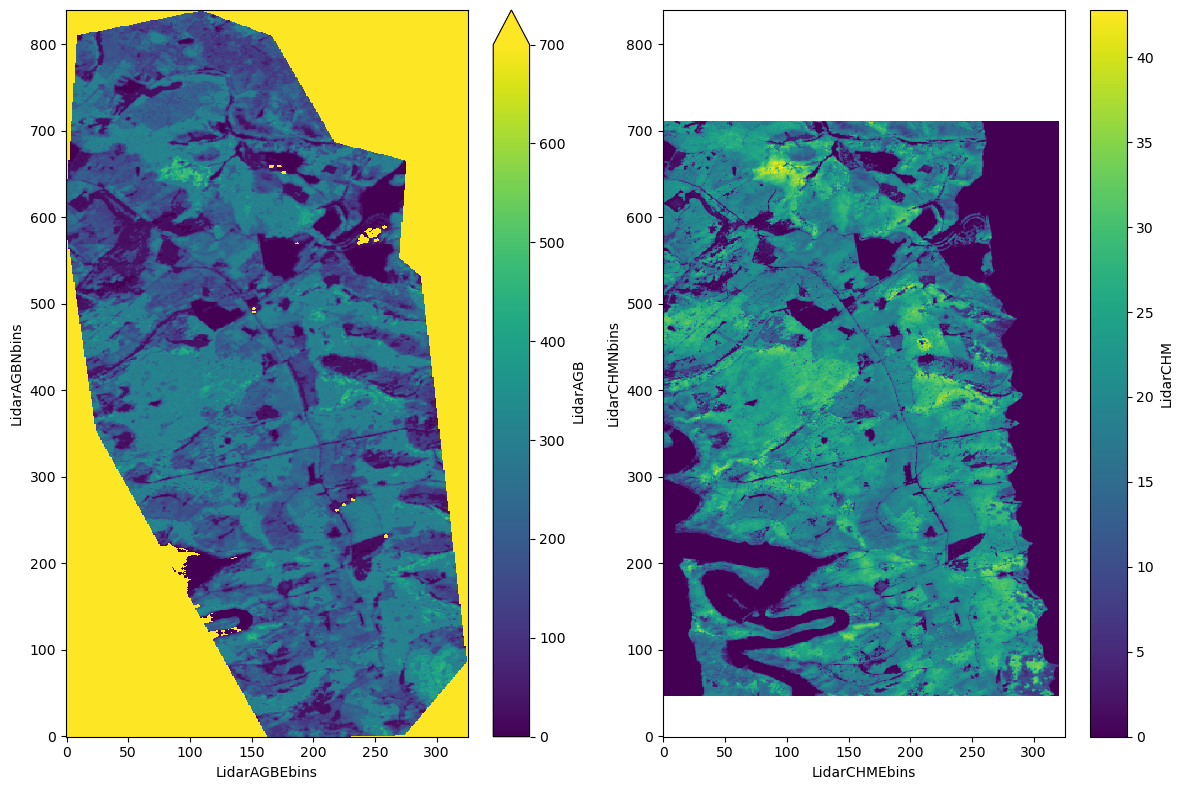

In [44]:
fig,ax = plt.subplots(1,2,figsize=(12,8))
dlidar.LidarAGB.plot(ax=ax[0], vmax=700)
dlidar.LidarCHM.plot(ax=ax[1])
plt.tight_layout()
plt.show()

# AnglesUTM

In [78]:
# reads a single netCDF file
dAngle = xr.open_dataset("AnglesUTM.nc")

In [79]:
# data details along with metadata
dAngle

<xarray.Dataset> Size: 9MB
Dimensions:           (AzimuthSlopeNWEbins: 840, AzimuthSlopeNWNbins: 326,
                       GroundSlopeNWEbins: 840, GroundSlopeNWNbins: 326,
                       OffNadirNWEbins: 840, OffNadirNWNbins: 326,
                       IncidenceAngleNWEbins: 840, IncidenceAngleNWNbins: 326,
                       AzimuthSlopeSEEbins: 840, AzimuthSlopeSENbins: 326,
                       GroundSlopeSEEbins: 840, GroundSlopeSENbins: 326,
                       OffNadirSEEbins: 840, OffNadirSENbins: 326,
                       IncidenceAngleSEEbins: 840, IncidenceAngleSENbins: 326,
                       EastingAxisEbins: 840, NorthingAxisNbins: 326)
Dimensions without coordinates: AzimuthSlopeNWEbins, AzimuthSlopeNWNbins,
                                GroundSlopeNWEbins, GroundSlopeNWNbins,
                                OffNadirNWEbins, OffNadirNWNbins,
                                IncidenceAngleNWEbins, IncidenceAngleNWNbins,
                                AzimuthSlopeSEEbins, AzimuthSlopeSENbins,
                                GroundSlopeSEEbins, GroundSlopeSENbins,
                                OffNadirSEEbins, OffNadirSENbins,
                                IncidenceAngleSEEbins, IncidenceAngleSENbins,
                                EastingAxisEbins, NorthingAxisNbins
Data variables:
    AzimuthSlopeNW    (AzimuthSlopeNWEbins, AzimuthSlopeNWNbins) float32 1MB ...
    GroundSlopeNW     (GroundSlopeNWEbins, GroundSlopeNWNbins) float32 1MB ...
    OffNadirNW        (OffNadirNWEbins, OffNadirNWNbins) float32 1MB ...
    IncidenceAngleNW  (IncidenceAngleNWEbins, IncidenceAngleNWNbins) float32 1MB ...
    AzimuthSlopeSE    (AzimuthSlopeSEEbins, AzimuthSlopeSENbins) float32 1MB ...
    GroundSlopeSE     (GroundSlopeSEEbins, GroundSlopeSENbins) float32 1MB ...
    OffNadirSE        (OffNadirSEEbins, OffNadirSENbins) float32 1MB ...
    IncidenceAngleSE  (IncidenceAngleSEEbins, IncidenceAngleSENbins) float32 1MB ...
    EastingAxis       (EastingAxisEbins) float32 3kB ...
    NorthingAxis      (NorthingAxisNbins) float32 1kB ...

In [80]:
# variables in the dataset
dAngle.data_vars

Data variables:
    AzimuthSlopeNW    (AzimuthSlopeNWEbins, AzimuthSlopeNWNbins) float32 1MB ...
    GroundSlopeNW     (GroundSlopeNWEbins, GroundSlopeNWNbins) float32 1MB ...
    OffNadirNW        (OffNadirNWEbins, OffNadirNWNbins) float32 1MB ...
    IncidenceAngleNW  (IncidenceAngleNWEbins, IncidenceAngleNWNbins) float32 1MB ...
    AzimuthSlopeSE    (AzimuthSlopeSEEbins, AzimuthSlopeSENbins) float32 1MB ...
    GroundSlopeSE     (GroundSlopeSEEbins, GroundSlopeSENbins) float32 1MB ...
    OffNadirSE        (OffNadirSEEbins, OffNadirSENbins) float32 1MB ...
    IncidenceAngleSE  (IncidenceAngleSEEbins, IncidenceAngleSENbins) float32 1MB ...
    EastingAxis       (EastingAxisEbins) float32 3kB ...
    NorthingAxis      (NorthingAxisNbins) float32 1kB ...

In [96]:
# shape of numpy array
print("AzimuthSlopeNW is:", dAngle.AzimuthSlopeNW.data.shape)
print("GroundSlopeNW is:", dAngle.GroundSlopeNW.data.shape)
print("OffNadirNW is:", dAngle.OffNadirNW.data.shape)

AzimuthSlopeNW is: (840, 326)
GroundSlopeNW is: (840, 326)
OffNadirNW is: (840, 326)


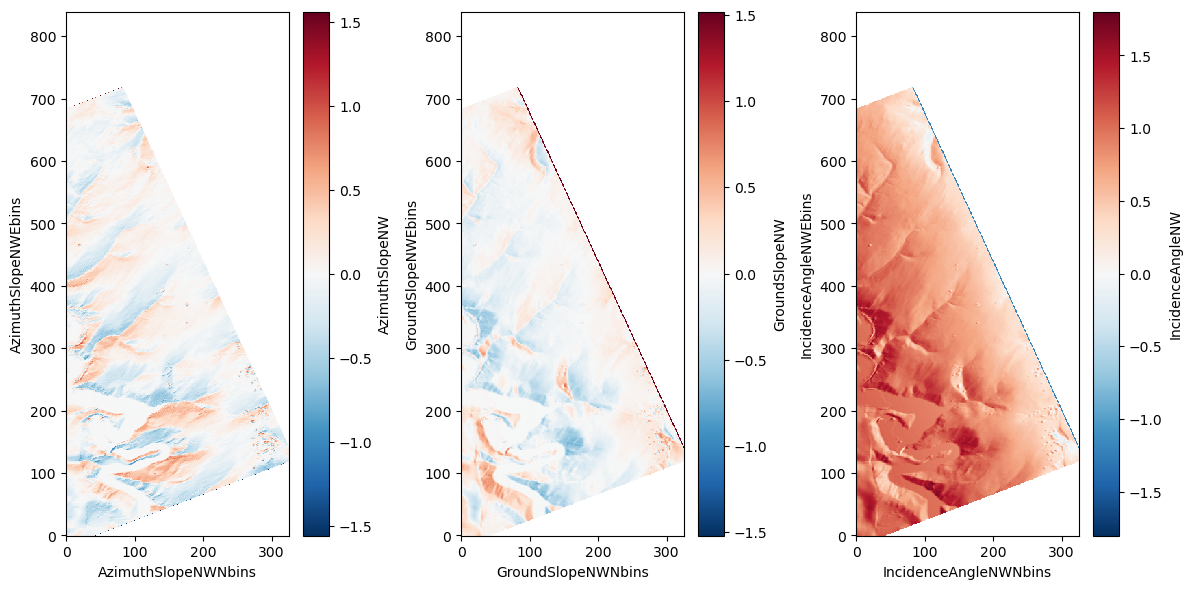

<Figure size 640x480 with 0 Axes>

In [111]:
fig,ax = plt.subplots(1,3,figsize=(12,6))
dAngle.AzimuthSlopeNW.plot(ax=ax[0])
dAngle.GroundSlopeNW.plot(ax=ax[1])
dAngle.IncidenceAngleNW.plot(ax=ax[2])
plt.tight_layout()
plt.show()
# plt.savefig('NW_AzimuthSlope_GroundSlope_IncidenceAngle.png')

In [112]:
# shape of numpy array
print("AzimuthSlopeSE is:", dAngle.AzimuthSlopeSE.data.shape)
print("GroundSlopeSE is:", dAngle.GroundSlopeSE.data.shape)
print("OffNadirSE is:", dAngle.OffNadirSE.data.shape)

AzimuthSlopeSE is: (840, 326)
GroundSlopeSE is: (840, 326)
OffNadirSE is: (840, 326)


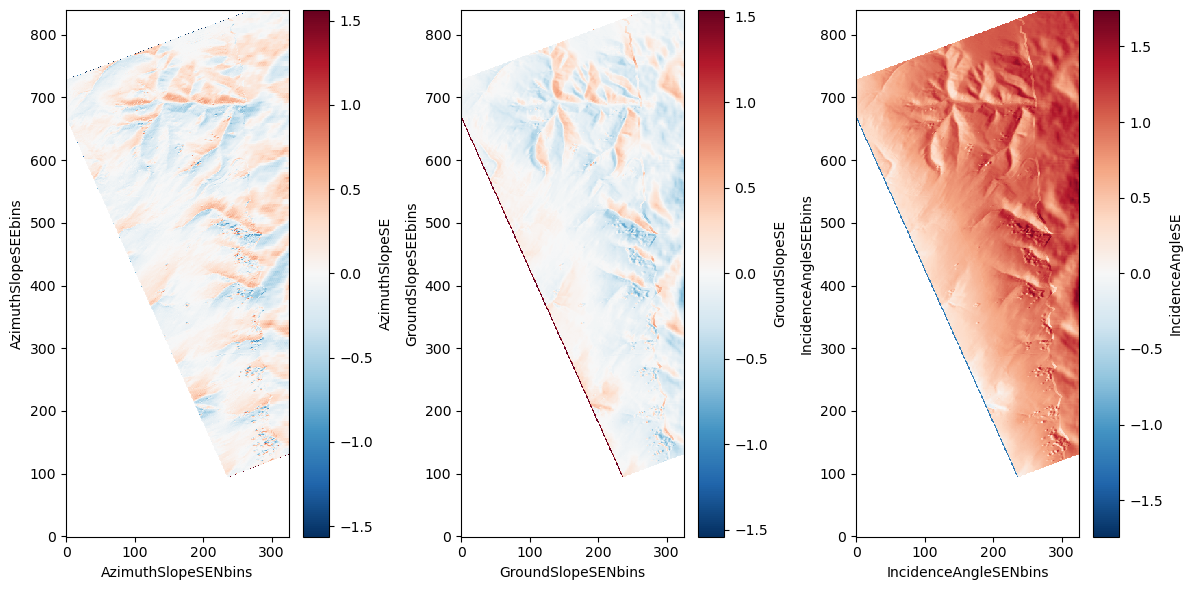

In [113]:
fig,ax = plt.subplots(1,3,figsize=(12,6))
dAngle.AzimuthSlopeSE.plot(ax=ax[0])
dAngle.GroundSlopeSE.plot(ax=ax[1])
dAngle.IncidenceAngleSE.plot(ax=ax[2])
plt.tight_layout()
plt.show()

## PcubeDeRampedUTM

In [53]:
# reads a single netCDF file
dPcubeDeramp = xr.open_dataset("PcubeDeRampedUTM.nc")

In [69]:
# data details along with metadata
# dPcubeDeramp
# variables in the dataset
dPcubeDeramp.data_vars

Data variables:
    TomoDeRampedNWMonoHH-10m  (TomoDeRampedNWMonoHH-10mEbins, TomoDeRampedNWMonoHH-10mNbins) float32 1MB ...
    TomoDeRampedNWMonoHH-8m   (TomoDeRampedNWMonoHH-8mEbins, TomoDeRampedNWMonoHH-8mNbins) float32 1MB ...
    TomoDeRampedNWMonoHH-6m   (TomoDeRampedNWMonoHH-6mEbins, TomoDeRampedNWMonoHH-6mNbins) float32 1MB ...
    TomoDeRampedNWMonoHH-4m   (TomoDeRampedNWMonoHH-4mEbins, TomoDeRampedNWMonoHH-4mNbins) float32 1MB ...
    TomoDeRampedNWMonoHH-2m   (TomoDeRampedNWMonoHH-2mEbins, TomoDeRampedNWMonoHH-2mNbins) float32 1MB ...
    TomoDeRampedNWMonoHH0m    (TomoDeRampedNWMonoHH0mEbins, TomoDeRampedNWMonoHH0mNbins) float32 1MB ...
    TomoDeRampedNWMonoHH2m    (TomoDeRampedNWMonoHH2mEbins, TomoDeRampedNWMonoHH2mNbins) float32 1MB ...
    TomoDeRampedNWMonoHH4m    (TomoDeRampedNWMonoHH4mEbins, TomoDeRampedNWMonoHH4mNbins) float32 1MB ...
    TomoDeRampedNWMonoHH6m    (TomoDeRampedNWMonoHH6mEbins, TomoDeRampedNWMonoHH6mNbins) float32 1MB ...
    TomoDeRampedNWMonoHH8m 

In [55]:
# shape of numpy array
print("TomoDeRampedNWMonoHH0m is:", dPcubeDeramp.TomoDeRampedNWMonoHH0m.data.shape)
print("TomoDeRampedNWMonoHH10m is:", dPcubeDeramp.TomoDeRampedNWMonoHH10m.data.shape)
print("TomoDeRampedNWMonoHH20m is:", dPcubeDeramp.TomoDeRampedNWMonoHH20m.data.shape)
print("TomoDeRampedNWMonoHH30m is:", dPcubeDeramp.TomoDeRampedNWMonoHH30m.data.shape)
print("TomoDeRampedNWMonoHH40m is:", dPcubeDeramp.TomoDeRampedNWMonoHH40m.data.shape)
print("TomoDeRampedNWMonoHH50m is:", dPcubeDeramp.TomoDeRampedNWMonoHH50m.data.shape)
print("TomoDeRampedNWMonoHH60m is:", dPcubeDeramp.TomoDeRampedNWMonoHH60m.data.shape)

TomoDeRampedNWMonoHH0m is: (840, 326)
TomoDeRampedNWMonoHH10m is: (840, 326)
TomoDeRampedNWMonoHH20m is: (840, 326)
TomoDeRampedNWMonoHH30m is: (840, 326)
TomoDeRampedNWMonoHH40m is: (840, 326)
TomoDeRampedNWMonoHH50m is: (840, 326)
TomoDeRampedNWMonoHH60m is: (840, 326)


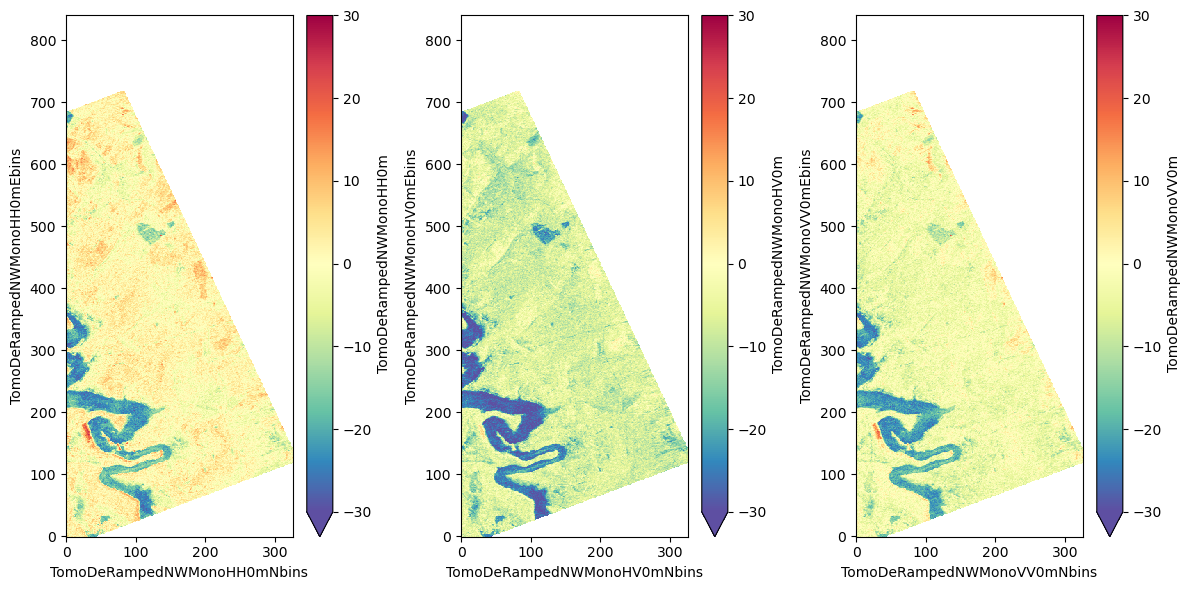

In [56]:
fig,ax = plt.subplots(1,3,figsize=(12,6))
dPcubeDeramp.TomoDeRampedNWMonoHH0m.plot(ax=ax[0], vmin=-30, vmax=30, cmap="Spectral_r")
dPcubeDeramp.TomoDeRampedNWMonoHV0m.plot(ax=ax[1], vmin=-30, vmax=30, cmap="Spectral_r")
dPcubeDeramp.TomoDeRampedNWMonoVV0m.plot(ax=ax[2], vmin=-30, vmax=30, cmap="Spectral_r")
plt.tight_layout()
plt.show()

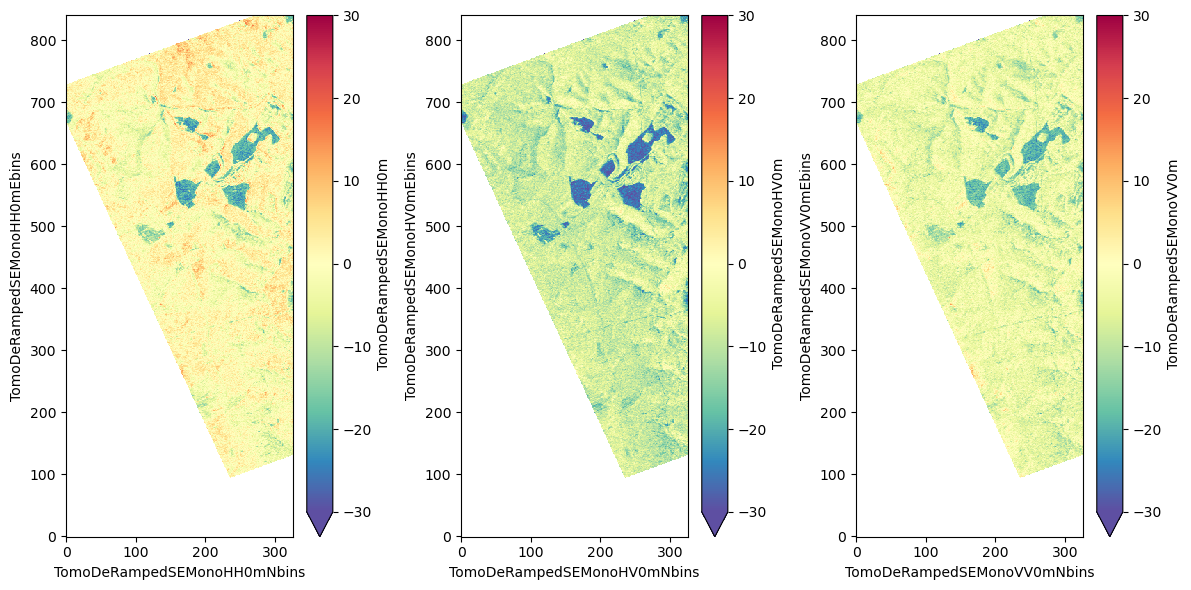

In [57]:
fig,ax = plt.subplots(1,3,figsize=(12,6))
dPcubeDeramp.TomoDeRampedSEMonoHH0m.plot(ax=ax[0], vmin=-30, vmax=30, cmap="Spectral_r")
dPcubeDeramp.TomoDeRampedSEMonoHV0m.plot(ax=ax[1], vmin=-30, vmax=30, cmap="Spectral_r")
dPcubeDeramp.TomoDeRampedSEMonoVV0m.plot(ax=ax[2], vmin=-30, vmax=30, cmap="Spectral_r")
plt.tight_layout()
plt.show()

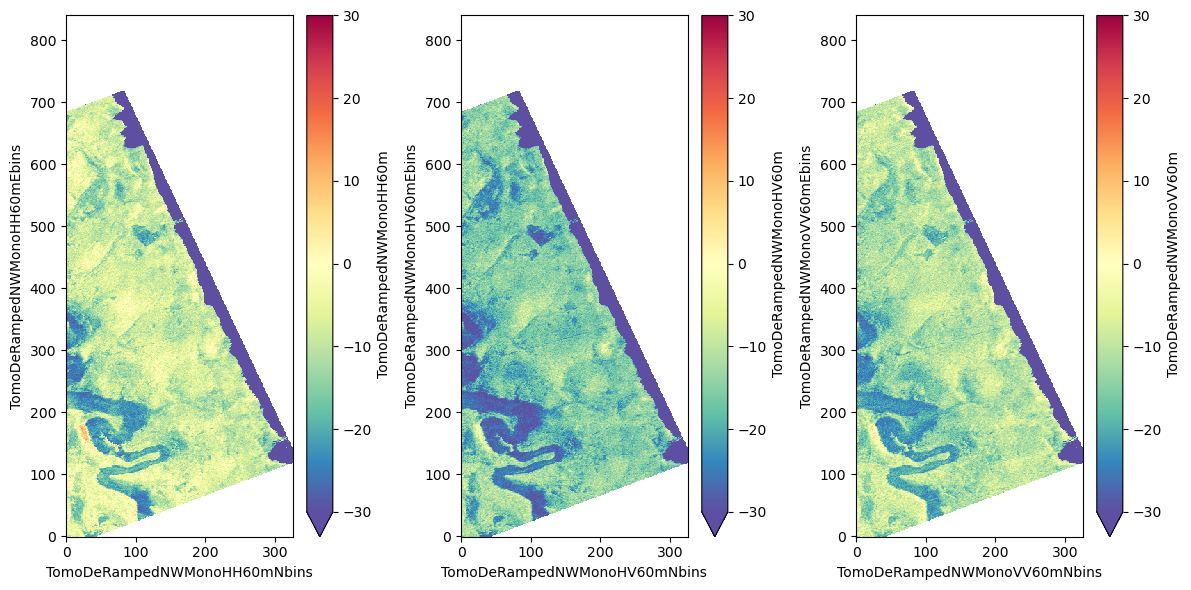

In [58]:
fig,ax = plt.subplots(1,3,figsize=(12,6))
dPcubeDeramp.TomoDeRampedNWMonoHH60m.plot(ax=ax[0], vmin=-30, vmax=30, cmap="Spectral_r")
dPcubeDeramp.TomoDeRampedNWMonoHV60m.plot(ax=ax[1], vmin=-30, vmax=30, cmap="Spectral_r")
dPcubeDeramp.TomoDeRampedNWMonoVV60m.plot(ax=ax[2], vmin=-30, vmax=30, cmap="Spectral_r")
plt.tight_layout()
plt.show()

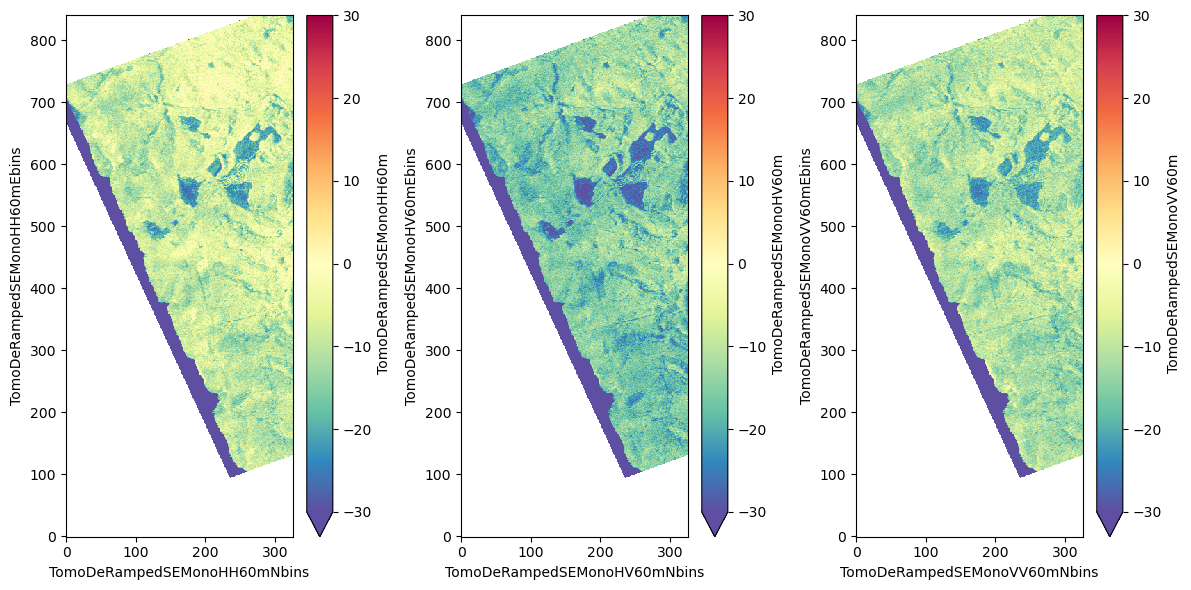

In [59]:
fig,ax = plt.subplots(1,3,figsize=(12,6))
dPcubeDeramp.TomoDeRampedSEMonoHH60m.plot(ax=ax[0], vmin=-30, vmax=30, cmap="Spectral_r")
dPcubeDeramp.TomoDeRampedSEMonoHV60m.plot(ax=ax[1], vmin=-30, vmax=30, cmap="Spectral_r")
dPcubeDeramp.TomoDeRampedSEMonoVV60m.plot(ax=ax[2], vmin=-30, vmax=30, cmap="Spectral_r")
plt.tight_layout()
plt.show()

In [60]:
# reads a single netCDF file
dPcubeNorm = xr.open_dataset("PcubeNormUTM.nc")

In [63]:
# data details along with metadata
# dPcubeNorm
# variables in the dataset
dPcubeNorm.data_vars

Data variables:
    TomoNormalizedNWMonoHH-10m  (TomoNormalizedNWMonoHH-10mEbins, TomoNormalizedNWMonoHH-10mNbins) float32 1MB ...
    TomoNormalizedNWMonoHH-8m   (TomoNormalizedNWMonoHH-8mEbins, TomoNormalizedNWMonoHH-8mNbins) float32 1MB ...
    TomoNormalizedNWMonoHH-6m   (TomoNormalizedNWMonoHH-6mEbins, TomoNormalizedNWMonoHH-6mNbins) float32 1MB ...
    TomoNormalizedNWMonoHH-4m   (TomoNormalizedNWMonoHH-4mEbins, TomoNormalizedNWMonoHH-4mNbins) float32 1MB ...
    TomoNormalizedNWMonoHH-2m   (TomoNormalizedNWMonoHH-2mEbins, TomoNormalizedNWMonoHH-2mNbins) float32 1MB ...
    TomoNormalizedNWMonoHH0m    (TomoNormalizedNWMonoHH0mEbins, TomoNormalizedNWMonoHH0mNbins) float32 1MB ...
    TomoNormalizedNWMonoHH2m    (TomoNormalizedNWMonoHH2mEbins, TomoNormalizedNWMonoHH2mNbins) float32 1MB ...
    TomoNormalizedNWMonoHH4m    (TomoNormalizedNWMonoHH4mEbins, TomoNormalizedNWMonoHH4mNbins) float32 1MB ...
    TomoNormalizedNWMonoHH6m    (TomoNormalizedNWMonoHH6mEbins, TomoNormalizedNWMono

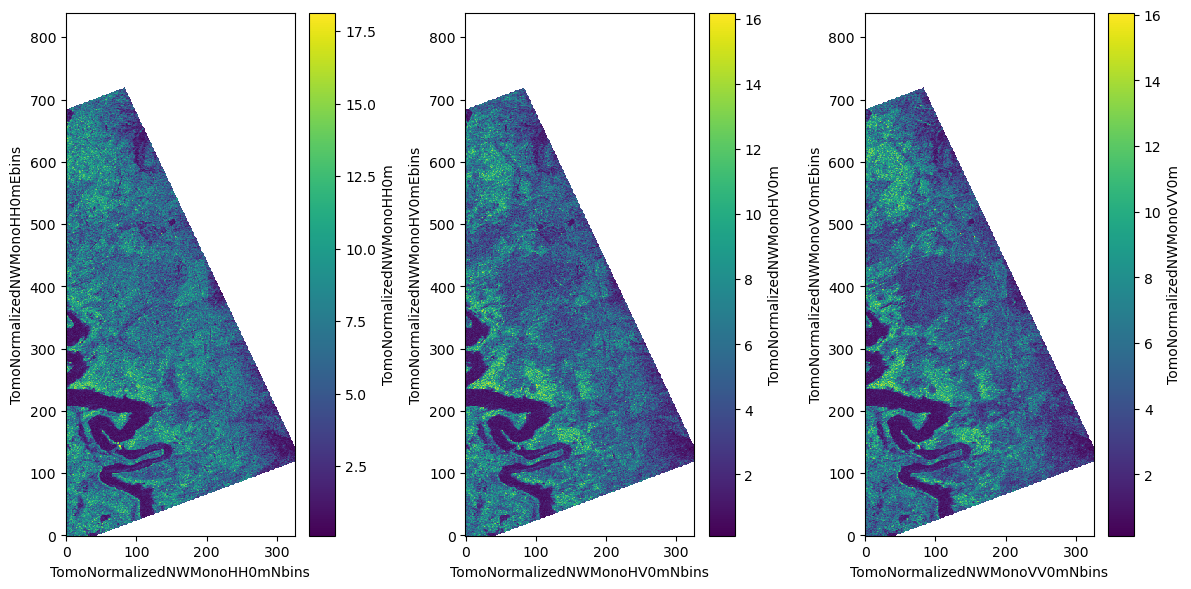

In [71]:
fig,ax = plt.subplots(1,3,figsize=(12,6))
dPcubeNorm.TomoNormalizedNWMonoHH0m.plot(ax=ax[0])
dPcubeNorm.TomoNormalizedNWMonoHV0m.plot(ax=ax[1])
dPcubeNorm.TomoNormalizedNWMonoVV0m.plot(ax=ax[2])
plt.tight_layout()
plt.show()